# Mock Lab Exam 2 — SOLUTION

One flow over the lab datasets (breast cancer, Wine, insurance), built from the tasks that repeat across PyLab 4–7. Suggested time: 75 minutes, no notes.

The imports are given. Run the cell below first.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.compose import ColumnTransformer
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import roc_curve, auc
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

---
## Part A — Classification on `data/breast_cancer.csv` (Labs 5, 6, 7)

---
## A.1 Load, inspect, clean

### Task 1 — Load and inspect

Read `data/breast_cancer.csv` into `df`. Print its shape, call `df.info()` and show the first 5 rows.

In [2]:
df = pd.read_csv("data/breast_cancer.csv")
print(df.shape)
df.info()
df.head()

(569, 33)
<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    str    
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             56

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


> **Not:** `info()` sütun tiplerini ve boş olmayan satır sayısını gösterir. `Unnamed: 32` sütununda 0 non-null görürsün: tamamen boş.

### Task 2 — Missing values

Print the number of missing values per column. Then print **only** the columns that have at least one missing value.

In [3]:
print(df.isnull().sum())

missing = df.isnull().sum()
print(missing[missing > 0])

id                           0
diagnosis                    0
radius_mean                  0
texture_mean                 0
perimeter_mean               0
area_mean                    0
smoothness_mean              0
compactness_mean             0
concavity_mean               0
concave points_mean          0
symmetry_mean                0
fractal_dimension_mean       0
radius_se                    0
texture_se                   0
perimeter_se                 0
area_se                      0
smoothness_se                0
compactness_se               0
concavity_se                 0
concave points_se            0
symmetry_se                  0
fractal_dimension_se         0
radius_worst                 0
texture_worst                0
perimeter_worst              0
area_worst                   0
smoothness_worst             0
compactness_worst            0
concavity_worst              0
concave points_worst         0
symmetry_worst               0
fractal_dimension_worst      0
Unnamed:

> **Not:** `isnull()` her hücre için True/False verir, `.sum()` sütun bazında True'ları sayar. Filtre: `seri[seri > 0]`.

### Task 3 — Drop useless columns

Drop `id` and `Unnamed: 32` in place and show the head.

In [4]:
df.drop(columns=['id', 'Unnamed: 32'], inplace=True)
df.head()

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


> **Not:** Bu hücreyi ikinci kez çalıştırırsan KeyError alırsın; veriyi baştan oku.

### Task 4 — Class distribution and encoding

Print the value counts of `diagnosis`. Map `B → 0`, `M → 1`, print the value counts again, then show `df.describe()`.

In [5]:
print(df["diagnosis"].value_counts())
df["diagnosis"] = df["diagnosis"].map({'B': 0, 'M': 1})
print(df["diagnosis"].value_counts())
df.describe()

diagnosis
B    357
M    212
Name: count, dtype: int64
diagnosis
0    357
1    212
Name: count, dtype: int64


,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,0.372583,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,0.483918,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,0.000000,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,0.000000,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,0.000000,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,1.000000,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,1.000000,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


> **Not:** `map` sözlükteki karşılığı yazar. Sözlükte olmayan değer NaN olur, o yüzden harfleri birebir doğru yaz.

### Task 5 — A histogram by class

Figure 8×5: two overlapping histograms of `radius_mean` (25 bins, `alpha=0.7`, black edges), one for `diagnosis == 0` (steelblue, label `'Benign (0)'`) and one for `diagnosis == 1` (crimson, label `'Malignant (1)'`). Add a title, axis labels and a legend.

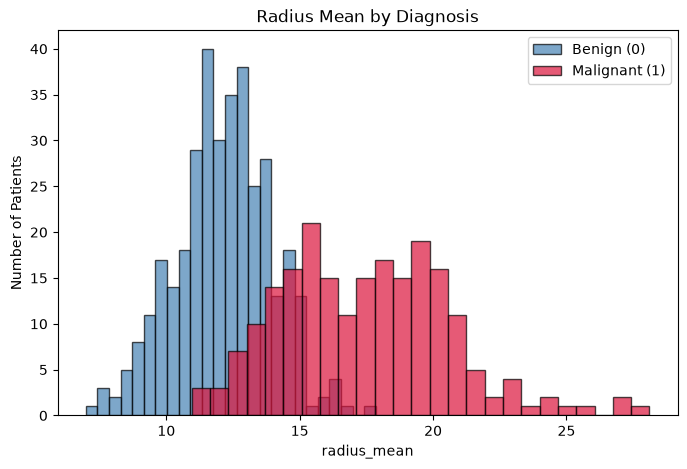

In [6]:
plt.figure(figsize=(8, 5))
plt.hist(df[df['diagnosis'] == 0]['radius_mean'], bins=25, alpha=0.7, color='steelblue',
         label='Benign (0)', edgecolor='black')
plt.hist(df[df['diagnosis'] == 1]['radius_mean'], bins=25, alpha=0.7, color='crimson',
         label='Malignant (1)', edgecolor='black')
plt.title('Radius Mean by Diagnosis')
plt.xlabel('radius_mean')
plt.ylabel('Number of Patients')
plt.legend()
plt.show()

> **Not:** Grafik kalıbı hep aynı: `figure` → çizim → `title`, `xlabel`, `ylabel`, `legend` → `show`. Satır filtresi: `df[df['sütun'] == değer]`.

---
## A.2 Split and scale

### Task 6 — Features, target, split, scale

Create `X` and `y` (`diagnosis` is the target). Split with `test_size=0.2`, `random_state=42`, stratified on `y`. Create `scaler`, `X_train_scaled` (fit + transform) and `X_test_scaled` (transform only). Print the shapes of the two scaled arrays.

In [7]:
X = df.drop('diagnosis', axis=1)
y = df['diagnosis']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print(X_train_scaled.shape, X_test_scaled.shape)

(455, 30) (114, 30)


> **Not:** En çok hata yapılan yer: train'de `fit_transform`, test'te sadece `transform`. Sıra: X_train, X_test, y_train, y_test.

---
## A.3 KNN (Lab 5)

### Task 7 — Train KNN (K=5) and evaluate

Create `knn_classifier` with 5 neighbours, fit on the scaled training data, predict `y_pred_c`. Print the accuracy (4 decimals) and the classification report with target names `['Benign (0)', 'Malignant (1)']`.

In [8]:
knn_classifier = KNeighborsClassifier(n_neighbors=5)
knn_classifier.fit(X_train_scaled, y_train)
y_pred_c = knn_classifier.predict(X_test_scaled)

print(f"Accuracy: {accuracy_score(y_test, y_pred_c):.4f}\n")
print(classification_report(y_test, y_pred_c, target_names=['Benign (0)', 'Malignant (1)']))

Accuracy: 0.9561

               precision    recall  f1-score   support

   Benign (0)       0.95      0.99      0.97        72
Malignant (1)       0.97      0.90      0.94        42

     accuracy                           0.96       114
    macro avg       0.96      0.95      0.95       114
 weighted avg       0.96      0.96      0.96       114



> **Not:** Her modelde aynı üç satır: oluştur → `fit(X_train, y_train)` → `predict(X_test)`. Metriklerde sıra `(y_test, y_pred)`.

### Task 8 — Confusion matrix

Compute `cm` and plot it with display labels `['Benign', 'Malignant']`, `cmap='Blues'` and a title.

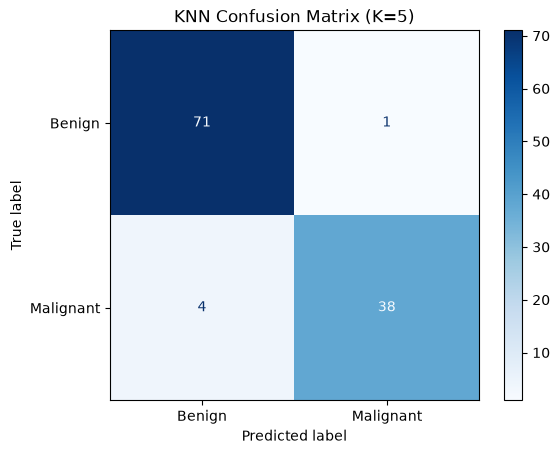

In [9]:
cm = confusion_matrix(y_test, y_pred_c)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Benign', 'Malignant'])
disp.plot(cmap='Blues')
plt.title("KNN Confusion Matrix (K=5)")
plt.show()

### Task 9 — Error rate for K = 1 … 29 and the elbow plot

For every K from 1 to 29 train a KNN and store the test error rate (mean of `pred != y_test`) in `error_rates`. Figure 10×5: plot the error rate against K (dashed line, circle markers), with title, axis labels, x ticks at every K and a light grid.

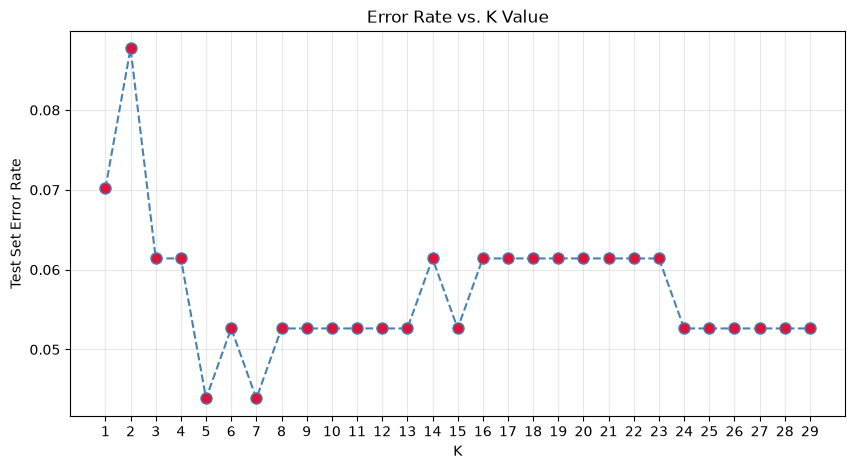

In [10]:
error_rates = []
k_values = range(1, 30)

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)
    pred_i = knn.predict(X_test_scaled)
    error_rates.append(np.mean(pred_i != y_test))

plt.figure(figsize=(10, 5))
plt.plot(k_values, error_rates, color='steelblue', linestyle='dashed', marker='o',
         markerfacecolor='crimson', markersize=8)
plt.title('Error Rate vs. K Value')
plt.xlabel('K')
plt.ylabel('Test Set Error Rate')
plt.xticks(k_values)
plt.grid(True, alpha=0.3)
plt.show()

> **Not:** `range(1, 30)` 1'den 29'a kadar gider (son sayı dahil değil). Hata oranı = yanlış tahminlerin ortalaması.

---
## A.4 Logistic regression, threshold, ROC (Lab 6)

### Task 10 — Fit, predict, probabilities, custom threshold

Create `log_reg = LogisticRegression()`, fit on the scaled training data, store hard predictions in `y_pred`. Store the probability of **class 1** in `y_probabilities_class1`. With `threshold = 0.3` create `y_pred_custom` (1 where the probability is ≥ threshold, else 0). Print the classification report of `y_pred` and of `y_pred_custom`.

In [11]:
log_reg = LogisticRegression()
log_reg.fit(X_train_scaled, y_train)
y_pred = log_reg.predict(X_test_scaled)

y_probabilities_class1 = log_reg.predict_proba(X_test_scaled)[:, 1]

threshold = 0.3
y_pred_custom = (y_probabilities_class1 >= threshold).astype(int)

print(classification_report(y_test, y_pred, target_names=['Benign (0)', 'Malignant (1)']))
print(classification_report(y_test, y_pred_custom, target_names=['Benign (0)', 'Malignant (1)']))

               precision    recall  f1-score   support

   Benign (0)       0.96      0.99      0.97        72
Malignant (1)       0.97      0.93      0.95        42

     accuracy                           0.96       114
    macro avg       0.97      0.96      0.96       114
 weighted avg       0.97      0.96      0.96       114

               precision    recall  f1-score   support

   Benign (0)       0.99      0.99      0.99        72
Malignant (1)       0.98      0.98      0.98        42

     accuracy                           0.98       114
    macro avg       0.98      0.98      0.98       114
 weighted avg       0.98      0.98      0.98       114



> **Not:** `predict_proba` iki sütun döner: sütun 0 = sınıf 0 olasılığı, sütun 1 = sınıf 1. `[:, 1]` ikinci sütunu alır. Threshold düşünce recall artar, precision düşer.

### Task 11 — ROC curve and AUC

Compute `fpr, tpr, thresholds` and `roc_auc`. Figure 7×5: plot the ROC curve (label showing the AUC with 4 decimals) and the dashed diagonal labelled `'Random Guessing'`. Axis labels, title, legend at lower right.

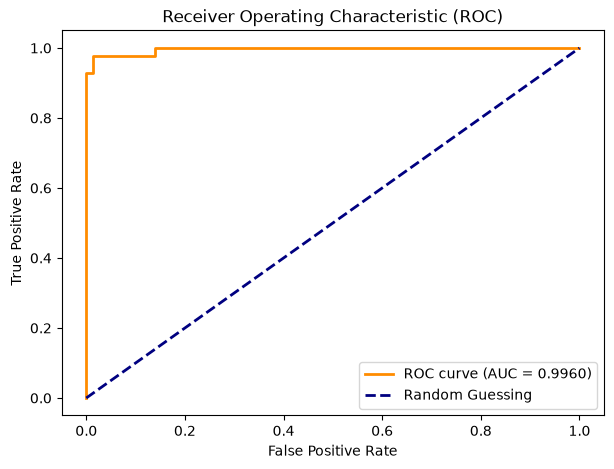

In [12]:
fpr, tpr, thresholds = roc_curve(y_test, y_probabilities_class1)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Guessing')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC)')
plt.legend(loc="lower right")
plt.show()

> **Not:** `roc_curve` hard tahmin değil **olasılık** ister. `auc(fpr, tpr)` eğrinin altındaki alan; 1'e yakınsa iyi.

### Task 12 — 5-fold cross-validation

Run 5-fold cross-validation of `log_reg` on the scaled training data scored by F1; store in `cv_scores`. Print the fold scores, the mean and the standard deviation (4 decimals).

In [13]:
cv_scores = cross_val_score(log_reg, X_train_scaled, y_train, cv=5, scoring='f1')

print(f"Fold F1 scores : {np.round(cv_scores, 4)}")
print(f"Mean           : {cv_scores.mean():.4f}")
print(f"Std            : {cv_scores.std():.4f}")

Fold F1 scores : [0.9538 0.9855 0.9375 0.9706 0.9565]
Mean           : 0.9608
Std            : 0.0162


> **Not:** Regresyonda `scoring='r2'` yazılır. Lab 6 demo amaçlı tüm X'i scale edip veriyor; soru hangisini isterse onu ver.

---
## A.5 PCA, LDA, QDA (Lab 7)

### Task 13 — Full PCA and cumulative explained variance

Create `pca_full = PCA()` and fit it on `X_train_scaled`. Print `explained_variance_ratio_`. Figure 8×4: plot the cumulative explained variance (in %) against the number of components (circle markers, dashed line), with title, axis labels and a light grid.

[4.45935222e-01 1.85452555e-01 9.58464121e-02 6.59376825e-02
 5.62228616e-02 3.98848772e-02 2.21449317e-02 1.61400564e-02
 1.28478896e-02 1.16566138e-02 1.00835994e-02 9.05534747e-03
 7.92635285e-03 4.79482101e-03 3.04107016e-03 2.51299401e-03
 1.97524871e-03 1.74413404e-03 1.57346560e-03 1.05152270e-03
 9.95539341e-04 7.95814888e-04 7.84034550e-04 5.31246275e-04
 5.11862282e-04 2.64113057e-04 2.09992404e-04 5.03306942e-05
 2.52827614e-05 4.12638742e-06]


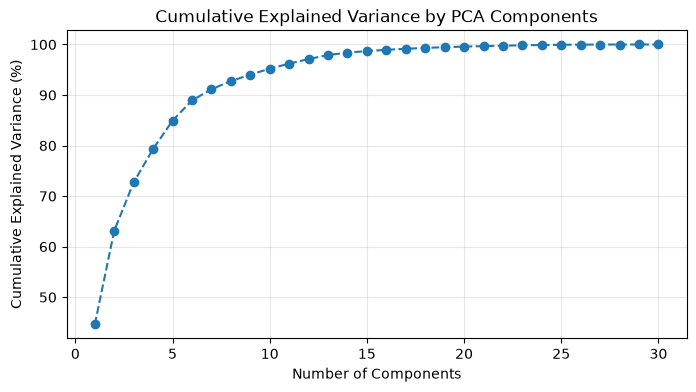

In [14]:
pca_full = PCA()
pca_full.fit(X_train_scaled)
print(pca_full.explained_variance_ratio_)

explained_variance = pca_full.explained_variance_ratio_ * 100

plt.figure(figsize=(8, 4))
plt.plot(range(1, len(explained_variance) + 1), np.cumsum(explained_variance), marker='o', linestyle='--')
plt.title('Cumulative Explained Variance by PCA Components')
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance (%)')
plt.grid(alpha=0.3)
plt.show()

> **Not:** Lab'da Wine verisi 13 özellikli olduğu için `range(1, 14)` yazıyordu. Burada 30 özellik var; `range(1, len(...) + 1)` her veri setinde çalışır. x ve y uzunluğu tutmazsa hata alırsın.

### Task 14 — PCA to 2 dimensions and a scatter plot

Create `pca_2d` with 2 components, `X_train_pca` (fit + transform of the scaled training data) and `X_test_pca` (transform only). Print the shape of `X_train_pca`. Figure 8×5: scatter of the two components coloured by `y_train` (`cmap='viridis'`, `edgecolor='k'`, `s=60`), title, axis labels, legend from `scatter.legend_elements()` titled `'Diagnosis'`.

(455, 2)


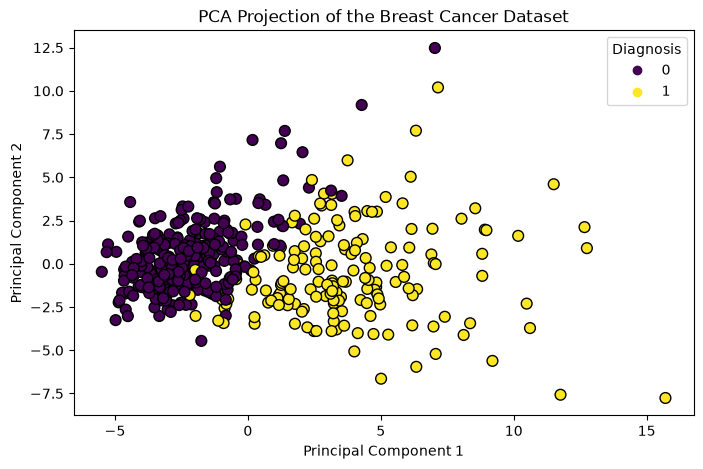

In [15]:
pca_2d = PCA(n_components=2)
X_train_pca = pca_2d.fit_transform(X_train_scaled)
X_test_pca = pca_2d.transform(X_test_scaled)
print(X_train_pca.shape)

plt.figure(figsize=(8, 5))
scatter = plt.scatter(X_train_pca[:, 0], X_train_pca[:, 1], c=y_train, cmap='viridis', edgecolor='k', s=60)
plt.title('PCA Projection of the Breast Cancer Dataset')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(*scatter.legend_elements(), title="Diagnosis")
plt.show()

> **Not:** PCA unsupervised: `fit_transform(X)` sadece X alır. `[:, 0]` birinci bileşen, `[:, 1]` ikinci.

### Task 15 — Logistic regression on the 2 principal components

Fit a new `LogisticRegression` (`log_reg_pca`) on `X_train_pca`, predict on `X_test_pca`, print the accuracy (4 decimals).

In [16]:
log_reg_pca = LogisticRegression()
log_reg_pca.fit(X_train_pca, y_train)
y_pred_pca = log_reg_pca.predict(X_test_pca)
print(f"Accuracy: {accuracy_score(y_test, y_pred_pca):.4f}")

Accuracy: 0.9474


### Task 16 — 1-D LDA and its histogram

Create `lda_1d` with 1 component and `X_train_lda` = fit + transform of the scaled training data (LDA is supervised). Figure 10×5: two overlapping histograms of the projected values (25 bins, `alpha=0.7`, black edges), one for `y_train == 0` (steelblue, `'Benign (Class 0)'`) and one for `y_train == 1` (crimson, `'Malignant (Class 1)'`). Title, axis labels, legend.

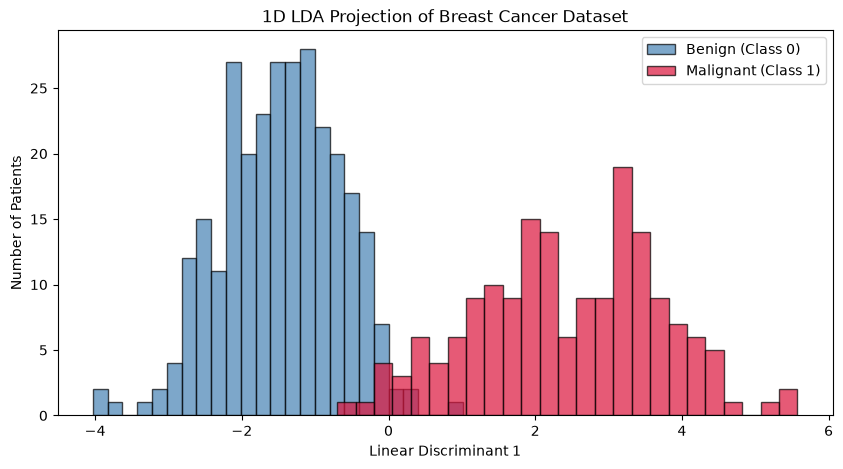

In [17]:
lda_1d = LinearDiscriminantAnalysis(n_components=1)
X_train_lda = lda_1d.fit_transform(X_train_scaled, y_train)

plt.figure(figsize=(10, 5))
plt.hist(X_train_lda[y_train == 0], bins=25, alpha=0.7, color='steelblue',
         label='Benign (Class 0)', edgecolor='black')
plt.hist(X_train_lda[y_train == 1], bins=25, alpha=0.7, color='crimson',
         label='Malignant (Class 1)', edgecolor='black')
plt.title('1D LDA Projection of Breast Cancer Dataset')
plt.xlabel('Linear Discriminant 1')
plt.ylabel('Number of Patients')
plt.legend()
plt.show()

> **Not:** LDA supervised: `fit_transform(X, y)` y de alır. En fazla K − 1 bileşen verir; 2 sınıfta 1. `n_components=2` yazarsan hata alırsın.

### Task 17 — Load, split and scale the Wine dataset

Load the dataset into `wine`. Create `X_w` as a DataFrame of `wine.data` with `wine.feature_names` as columns and `y_w` as `wine.target`. Print the shape of `X_w`. Split with `test_size=0.3`, `random_state=42`, stratified. Create `scaler_w`, `X_train_w_scaled` and `X_test_w_scaled`.

In [18]:
wine = load_wine()
X_w = pd.DataFrame(wine.data, columns=wine.feature_names)
y_w = wine.target
print(X_w.shape)

X_train_w, X_test_w, y_train_w, y_test_w = train_test_split(X_w, y_w, test_size=0.3, random_state=42, stratify=y_w)

scaler_w = StandardScaler()
X_train_w_scaled = scaler_w.fit_transform(X_train_w)
X_test_w_scaled = scaler_w.transform(X_test_w)

(178, 13)


> **Not:** sklearn'ün hazır veri seti: `.data` özellikler, `.target` etiketler, `.feature_names` sütun adları. CSV yok, `load_wine()` yeter.

### Task 18 — LDA to 2 dimensions on Wine and a scatter plot

Create `lda` with 2 components and `X_train_w_lda` = fit + transform of the scaled Wine training data. Figure 8×5: scatter of the two discriminants coloured by `y_train_w` (`cmap='viridis'`, `edgecolor='k'`, `s=60`), title, axis labels, legend titled `'Wine Class'`.

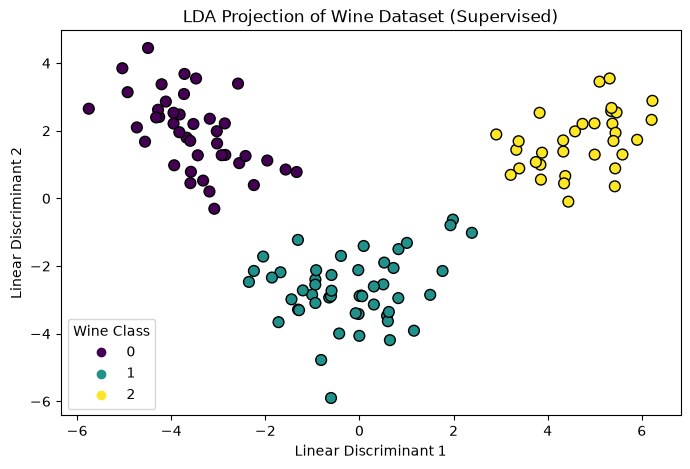

In [19]:
lda = LinearDiscriminantAnalysis(n_components=2)
X_train_w_lda = lda.fit_transform(X_train_w_scaled, y_train_w)

plt.figure(figsize=(8, 5))
scatter = plt.scatter(X_train_w_lda[:, 0], X_train_w_lda[:, 1], c=y_train_w, cmap='viridis', edgecolor='k', s=60)
plt.title('LDA Projection of Wine Dataset (Supervised)')
plt.xlabel('Linear Discriminant 1')
plt.ylabel('Linear Discriminant 2')
plt.legend(*scatter.legend_elements(), title="Wine Class")
plt.show()

> **Not:** Wine'da 3 sınıf var, K − 1 = 2 bileşen alınabilir.

### Task 19 — Compare LDA and QDA as classifiers (Wine)

Train `lda_clf = LinearDiscriminantAnalysis()` and `qda_clf = QuadraticDiscriminantAnalysis()` on the scaled Wine training data. Compute `acc_lda` and `acc_qda` on the test set and print both (4 decimals). Print the classification report of QDA.

In [20]:
lda_clf = LinearDiscriminantAnalysis()
lda_clf.fit(X_train_w_scaled, y_train_w)
y_pred_lda = lda_clf.predict(X_test_w_scaled)
acc_lda = accuracy_score(y_test_w, y_pred_lda)

qda_clf = QuadraticDiscriminantAnalysis()
qda_clf.fit(X_train_w_scaled, y_train_w)
y_pred_qda = qda_clf.predict(X_test_w_scaled)
acc_qda = accuracy_score(y_test_w, y_pred_qda)

print(f"LDA Accuracy: {acc_lda:.4f}")
print(f"QDA Accuracy: {acc_qda:.4f}\n")
print(classification_report(y_test_w, y_pred_qda))

LDA Accuracy: 0.9815
QDA Accuracy: 1.0000

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        18
           1       1.00      1.00      1.00        21
           2       1.00      1.00      1.00        15

    accuracy                           1.00        54
   macro avg       1.00      1.00      1.00        54
weighted avg       1.00      1.00      1.00        54



> **Not:** Lab QDA'yı Wine üzerinde yapıyor. Breast cancer verisinde QDA bu sklearn sürümünde `LinAlgError` (covariance not full rank) veriyor; sınavda bu hatayı görürsen `QuadraticDiscriminantAnalysis(reg_param=0.1)` yaz.

---
## Part B — Regression on `data/insurance.csv` (Labs 4, 5)

### Task 20 — Load, inspect, missing values

Read `data/insurance.csv` into `df_ins`. Call `info()`, print the missing values per column and show the head.

In [21]:
df_ins = pd.read_csv("data/insurance.csv")
df_ins.info()
print(df_ins.isnull().sum())
df_ins.head()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


### Task 21 — Binary encoding

Map `sex` (`female → 1`, `male → 0`) and `smoker` (`yes → 1`, `no → 0`). Show the head.

In [22]:
df_ins['sex'] = df_ins['sex'].map({'female': 1, 'male': 0})
df_ins['smoker'] = df_ins['smoker'].map({'yes': 1, 'no': 0})
df_ins.head()

,age,sex,bmi,children,smoker,region,charges
0,19,1,27.900,0,1,southwest,16884.92400
1,18,0,33.770,1,0,southeast,1725.55230
2,28,0,33.000,3,0,southeast,4449.46200
3,33,0,22.705,0,0,northwest,21984.47061
4,32,0,28.880,0,0,northwest,3866.85520


### Task 22 — Average charges by smoker: table and bar plot

Compute the mean `charges` for each value of `smoker` into `charges_smoker` (a DataFrame) and print it. Figure 6×4: bar plot of it with seaborn, with title and axis labels.

             charges
smoker              
0        8434.268298
1       32050.231832


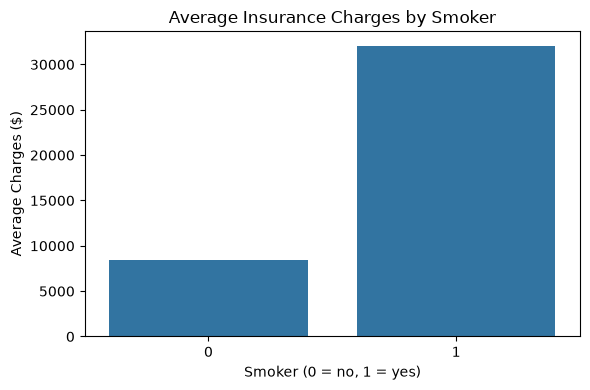

In [23]:
charges_smoker = df_ins.groupby('smoker')['charges'].mean().to_frame()
print(charges_smoker)

plt.figure(figsize=(6, 4))
sns.barplot(data=charges_smoker.reset_index(), x='smoker', y='charges')
plt.title("Average Insurance Charges by Smoker")
plt.xlabel("Smoker (0 = no, 1 = yes)")
plt.ylabel("Average Charges ($)")
plt.tight_layout()
plt.show()

> **Not:** `groupby('a')['b'].mean()` = a'nın her değeri için b'nin ortalaması. `reset_index()` grup sütununu normal sütuna çevirir ki seaborn `x=` ile bulabilsin.

### Task 23 — Features, target, split

Create `X_reg` and `y_reg` (`charges` is the target). Split with `test_size=0.2`, `random_state=42` (no stratify) and print the number of training and test samples.

In [24]:
X_reg = df_ins.drop('charges', axis=1)
y_reg = df_ins['charges']

X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(X_reg, y_reg, test_size=0.2, random_state=42)
print(len(X_train_r), len(X_test_r))

1070 268


> **Not:** Regresyonda `stratify` yok; hedef sürekli bir sayı, sınıf değil.

### Task 24 — Preprocess with a ColumnTransformer

Create `ohe = OneHotEncoder(drop='first', sparse_output=False)` and a `StandardScaler`. Build `preprocessor`: scale `age`, `bmi`, `children`; one-hot encode `region`; pass the rest through. Create `X_train_encoded` (fit + transform) and `X_test_encoded` (transform). Print the feature names.

In [25]:
ohe = OneHotEncoder(drop='first', sparse_output=False)
scaler_r = StandardScaler()

preprocessor = ColumnTransformer(
    transformers=[
        ('num', scaler_r, ['age', 'bmi', 'children']),
        ('cat', ohe, ['region'])
    ],
    remainder='passthrough'
)

X_train_encoded = preprocessor.fit_transform(X_train_r)
X_test_encoded = preprocessor.transform(X_test_r)
print(preprocessor.get_feature_names_out())

['num__age' 'num__bmi' 'num__children' 'cat__region_northwest'
 'cat__region_southeast' 'cat__region_southwest' 'remainder__sex'
 'remainder__smoker']


> **Not:** Her transformer bir üçlü: (isim, dönüştürücü, sütun listesi). `drop='first'` dummy variable trap'i önler. `remainder='passthrough'` yazmazsan `sex` ve `smoker` silinir.

### Task 25 — Multiple linear regression and metrics

Fit `mlr_model = LinearRegression()` on all encoded features and predict `y_pred_multi`. Print MAE, MSE, RMSE (2 decimals) and R² (4 decimals).

In [26]:
mlr_model = LinearRegression()
mlr_model.fit(X_train_encoded, y_train_r)
y_pred_multi = mlr_model.predict(X_test_encoded)

mae = mean_absolute_error(y_test_r, y_pred_multi)
mse = mean_squared_error(y_test_r, y_pred_multi)
rmse = np.sqrt(mse)
r2 = r2_score(y_test_r, y_pred_multi)

print(f"MAE  : {mae:.2f}")
print(f"MSE  : {mse:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"R²   : {r2:.4f}")

MAE  : 4181.19
MSE  : 33596915.85
RMSE : 5796.28
R²   : 0.7836


> **Not:** RMSE için ayrı fonksiyon yok: `np.sqrt(mse)`.

### Task 26 — Simple linear regression on age and its plot

Take only the age column (index 0) of the encoded arrays as `X_train_simple` and `X_test_simple` (keep them 2-D). Fit `slr_model`, predict `y_pred_simple`, print the intercept and the slope. Figure 8×5: scatter of the test points and the regression line (crimson), with title, axis labels and legend.

Intercept : 13346.09
Slope     : 3384.56


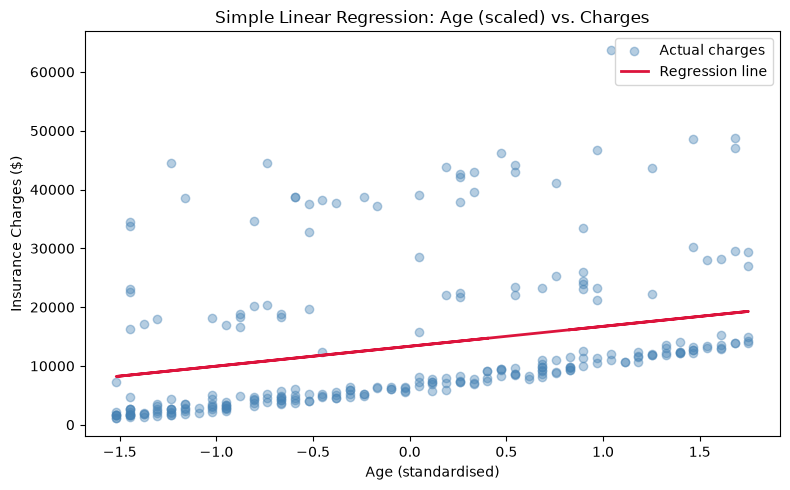

In [27]:
X_train_simple = X_train_encoded[:, [0]]
X_test_simple = X_test_encoded[:, [0]]

slr_model = LinearRegression()
slr_model.fit(X_train_simple, y_train_r)
y_pred_simple = slr_model.predict(X_test_simple)

print(f"Intercept : {slr_model.intercept_:.2f}")
print(f"Slope     : {slr_model.coef_[0]:.2f}")

plt.figure(figsize=(8, 5))
plt.scatter(X_test_simple, y_test_r, alpha=0.4, label='Actual charges', color='steelblue')
plt.plot(X_test_simple, y_pred_simple, color='crimson', linewidth=2, label='Regression line')
plt.title("Simple Linear Regression: Age (scaled) vs. Charges")
plt.xlabel("Age (standardised)")
plt.ylabel("Insurance Charges ($)")
plt.legend()
plt.tight_layout()
plt.show()

> **Not:** `[:, [0]]` çift köşeli parantezle 2 boyutlu kalır (N×1); sklearn X'i 2 boyutlu ister. `[:, 0]` yazarsan hata alırsın.

### Task 27 — Polynomial regression (degree 2)

Create `poly = PolynomialFeatures(degree=2, include_bias=False)`, build `X_train_poly` and `X_test_poly` from the encoded arrays, print the feature counts before and after. Fit `poly_model` and print its R² (4 decimals).

In [28]:
poly = PolynomialFeatures(degree=2, include_bias=False)
X_train_poly = poly.fit_transform(X_train_encoded)
X_test_poly = poly.transform(X_test_encoded)
print(X_train_encoded.shape[1], X_train_poly.shape[1])

poly_model = LinearRegression()
poly_model.fit(X_train_poly, y_train_r)
y_pred_poly = poly_model.predict(X_test_poly)
print(f"R² : {r2_score(y_test_r, y_pred_poly):.4f}")

8 44
R² : 0.8666


> **Not:** Polynomial regression = özellikleri çoğalt, sonra yine `LinearRegression`. Model hâlâ katsayılara göre lineer.

### Task 28 — KNN regressor (K=7)

Train `knn_regressor` with 7 neighbours on the encoded data, predict `y_pred_r`, print MAE, RMSE and R².

In [29]:
knn_regressor = KNeighborsRegressor(n_neighbors=7)
knn_regressor.fit(X_train_encoded, y_train_r)
y_pred_r = knn_regressor.predict(X_test_encoded)

print(f"MAE  : {mean_absolute_error(y_test_r, y_pred_r):.2f}")
print(f"RMSE : {np.sqrt(mean_squared_error(y_test_r, y_pred_r)):.2f}")
print(f"R²   : {r2_score(y_test_r, y_pred_r):.4f}")

MAE  : 4101.73
RMSE : 6918.85
R²   : 0.6917


---
## Part C — Short answers

### Task 29 — Why scale? Why stratify?

Why must the features be scaled before KNN and PCA? What does `stratify=y` do?

*Answer in one or two sentences.*

**Answer:** KNN uses distances and PCA uses variance, so a feature with a large scale would dominate; scaling puts all features on the same scale. `stratify=y` keeps the class proportions the same in the train and test sets.

### Task 30 — fit_transform vs transform

Why do we call `fit_transform` on the training set but only `transform` on the test set?

*Answer in one or two sentences.*

**Answer:** The scaler must learn the mean and standard deviation from the training data only. Fitting on the test set would leak information about the test data into the model (data leakage).

### Task 31 — Choosing K

What happens with a very small K and with a very large K?

*Answer in one or two sentences.*

**Answer:** Small K: low bias, high variance, sensitive to noise (overfitting). Large K: high bias, low variance, the boundary is too smooth and the majority class dominates (underfitting).

### Task 32 — Precision vs recall

Write the formulas. In cancer detection which one do we prioritise, and what does lowering the threshold do?

*Answer in one or two sentences.*

**Answer:** Precision = TP / (TP + FP). Recall = TP / (TP + FN). A false negative is worse, so we prioritise recall. Lowering the threshold increases recall and decreases precision.

### Task 33 — PCA vs LDA vs QDA

Supervised or not? What does each maximise or assume? Why can LDA give only 1 component here?

*Answer in one or two sentences.*

**Answer:** PCA: unsupervised, maximises variance, does not use y. LDA: supervised, maximises class separation, linear boundary, all classes share one covariance matrix. QDA: supervised, quadratic boundary, each class has its own covariance matrix. LDA gives at most K − 1 components; with 2 classes that is 1.

### Task 34 — Dummy variable trap

What is it and how do we avoid it?

*Answer in one or two sentences.*

**Answer:** One-hot encoding a column with k categories into k columns makes them perfectly collinear (they sum to 1). Use `drop='first'` to keep k − 1 columns.